# **Analisis de dominancia alternativas discretas- Seleccion carro eléçtrico**

Curso: Introducción al Análisis de Decisiones

Universidad Nacional de Colombia, Sede Medellín

Realizado por Profesora Patricia Jaramillo

Fecha actualización: 13 de Julio de 2026


Alternativas

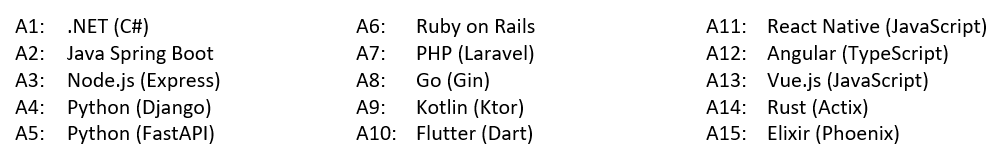

Criterios

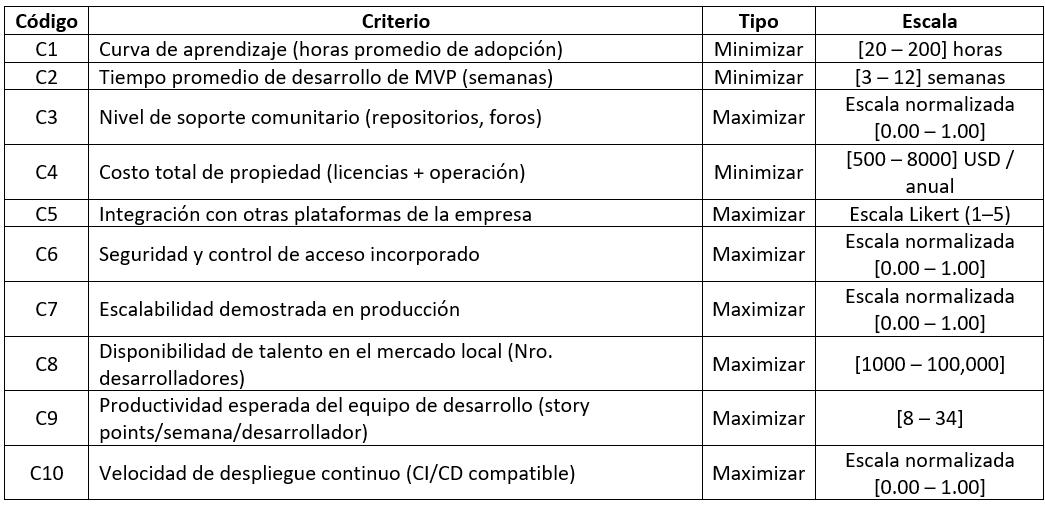

Matriz de Pagos

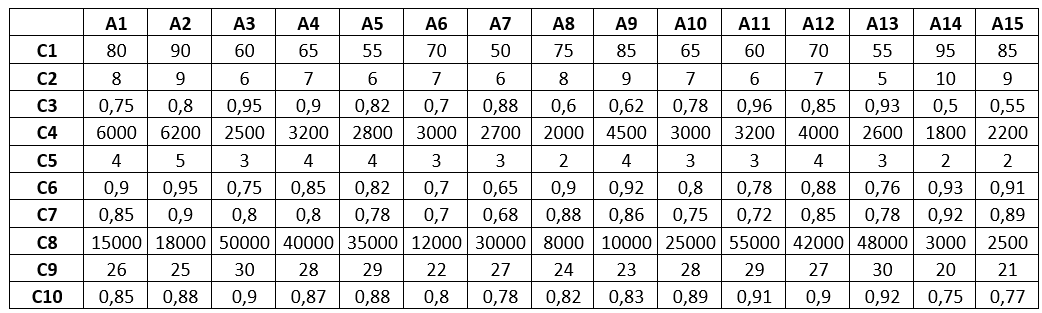

# **Análisis de dominancia**

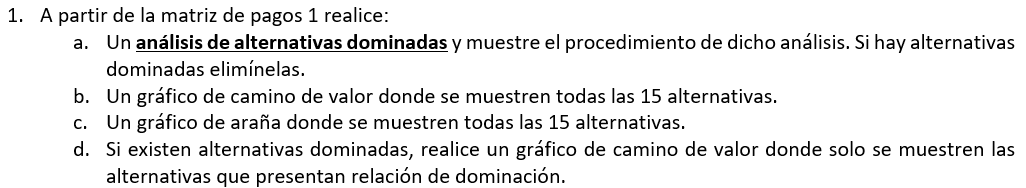

**Ejemplo**

*   Elemento de lista
*   Elemento de lista



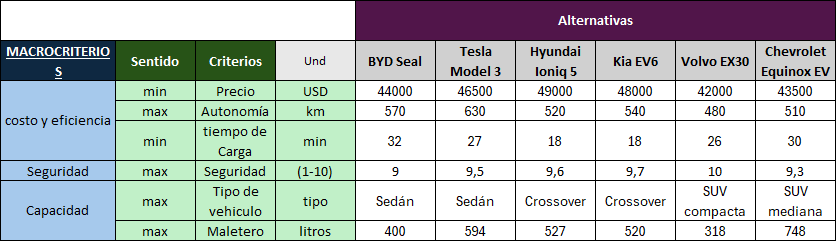

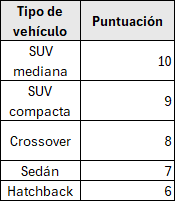

In [27]:
import pandas as pd


criterios = [
    "precio",      # C1
    "autonomia",   # C2
    "carga",       # C3
    "seguridad",   # C4
    "tipo",        # C5
    "maletero",    # C6
]

# Matriz de consecuencias
data = [
    [-44000, -46500, -49000, -48000, -42000, -43500],      # C1=Precio
    [570, 630, 520, 540, 480, 510],                        # C2=autonomia
    [-32, -27, -18, -18, -26, -30],                        # C3=tiempo de carga
    [9, 9.5, 9.6, 9.7, 10, 9.3],                           # C4=seguridad
    [7, 7, 8, 8, 9, 10],                                   # C5=tipo de vehiculo
    [400, 594, 527, 520, 318, 748],                        # C6=maletero

]

#
# Nombres de las alternativas
alternativas = ['BYD_seal', 'Tesla', 'Hyundai', 'Kia', 'Volvo',
           'Chevrolet']

# Crear el DataFrame
matriz_consecuencias = pd.DataFrame(data, index=criterios, columns=alternativas)

# Mostrar el DataFrame
print(matriz_consecuencias)


           BYD_seal    Tesla  Hyundai      Kia  Volvo  Chevrolet
precio       -50000 -46500.0 -49000.0 -48000.0 -42000   -43500.0
autonomia       100    630.0    520.0    540.0    480      510.0
carga           -50    -27.0    -18.0    -18.0    -26      -30.0
seguridad         7      9.5      9.6      9.7     10        9.3
tipo              7      7.0      8.0      8.0      9       10.0
maletero        200    594.0    527.0    520.0    318      748.0


**Código para normalizar la matriz de pagos por el valor máximo y el mínimo**

Se realiza la normalización de cada valor $Z_{ij}$ que corresponde al criterio $i$ en la alternativa $j$ mediante la siguiente expresión:


$$
Z_{ij}^{\text{norm}} = \frac{Z_{ij} - \min(Z_i)}{\max(Z_i) - \min(Z_i)}
$$

In [28]:
# Normalización por filas usando min-max
matriz_normalizada = matriz_consecuencias.apply(lambda fila: (fila - fila.min()) / (fila.max() - fila.min()), axis=1)
print("Matriz normalizada por filas (min-max):")
print(matriz_normalizada.round(3))


Matriz normalizada por filas (min-max):
           BYD_seal  Tesla  Hyundai    Kia  Volvo  Chevrolet
precio          0.0  0.438    0.125  0.250  1.000      0.812
autonomia       0.0  1.000    0.792  0.830  0.717      0.774
carga           0.0  0.719    1.000  1.000  0.750      0.625
seguridad       0.0  0.833    0.867  0.900  1.000      0.767
tipo            0.0  0.000    0.333  0.333  0.667      1.000
maletero        0.0  0.719    0.597  0.584  0.215      1.000


**Código para encontrar alternativas dominadas**

In [29]:

import numpy as np

# Transponer para trabajar más fácilmente: filas = alternativas
matriznormalizada_transpuesta = matriz_normalizada.T.copy()

# Lista que indica si cada criterio se debe maximizar (True) o minimizar (False)
objetivos = [True, True, True, True, True, True]

# Convertimos todo a numpy array para procesamiento eficiente
data = matriznormalizada_transpuesta.values
n_alternativas = data.shape[0]
dominadas = set()

# Comparamos cada par de alternativas
for i in range(n_alternativas):
    for j in range(n_alternativas):
        if i == j or j in dominadas:
            continue

        mejor_o_igual = True
        estrictamente_mejor = False

        for k, maximizar in enumerate(objetivos):
            val_i = data[i, k]
            val_j = data[j, k]

            if maximizar:
                if val_i < val_j:
                    mejor_o_igual = False
                    break
                elif val_i > val_j:
                    estrictamente_mejor = True
            else:
                if val_i > val_j:
                    mejor_o_igual = False
                    break
                elif val_i < val_j:
                    estrictamente_mejor = True

        if mejor_o_igual and estrictamente_mejor:
            dominadas.add(j)

# Mostrar alternativas dominadas
alternativas = matriznormalizada_transpuesta.index.tolist()
dominadas_labels = [alternativas[i] for i in dominadas]

print("Alternativas dominadas:", dominadas_labels)


Alternativas dominadas: ['BYD_seal']


**Código para encontrar alternativas dominantes**

In [30]:
# Convertimos a array
data = matriznormalizada_transpuesta.values
n_alternativas = data.shape[0]
alternativas = matriznormalizada_transpuesta.index.tolist()

# Diccionario para guardar quién domina a quién
dominadores = {alt: [] for alt in alternativas}

# Comparar cada par
for i in range(n_alternativas):
    for j in range(n_alternativas):
        if i == j:
            continue

        mejor_o_igual = True
        estrictamente_mejor = False

        for k, maximizar in enumerate(objetivos):
            val_i = data[i, k]
            val_j = data[j, k]

            if maximizar:
                if val_i < val_j:
                    mejor_o_igual = False
                    break
                elif val_i > val_j:
                    estrictamente_mejor = True
            else:
                if val_i > val_j:
                    mejor_o_igual = False
                    break
                elif val_i < val_j:
                    estrictamente_mejor = True

        if mejor_o_igual and estrictamente_mejor:
            dominadores[alternativas[j]].append(alternativas[i])

# Filtrar solo las alternativas que fueron dominadas
alternativas_dominadas = {alt: dom for alt, dom in dominadores.items() if len(dom) > 0}

# Mostrar resultado
for alt, quienes in alternativas_dominadas.items():
    print(f"La alternativa {alt} es dominada por: {', '.join(quienes)}")

La alternativa BYD_seal es dominada por: Tesla, Hyundai, Kia, Volvo, Chevrolet


**Gráfico de Camino de Valor para todas las alternativas**

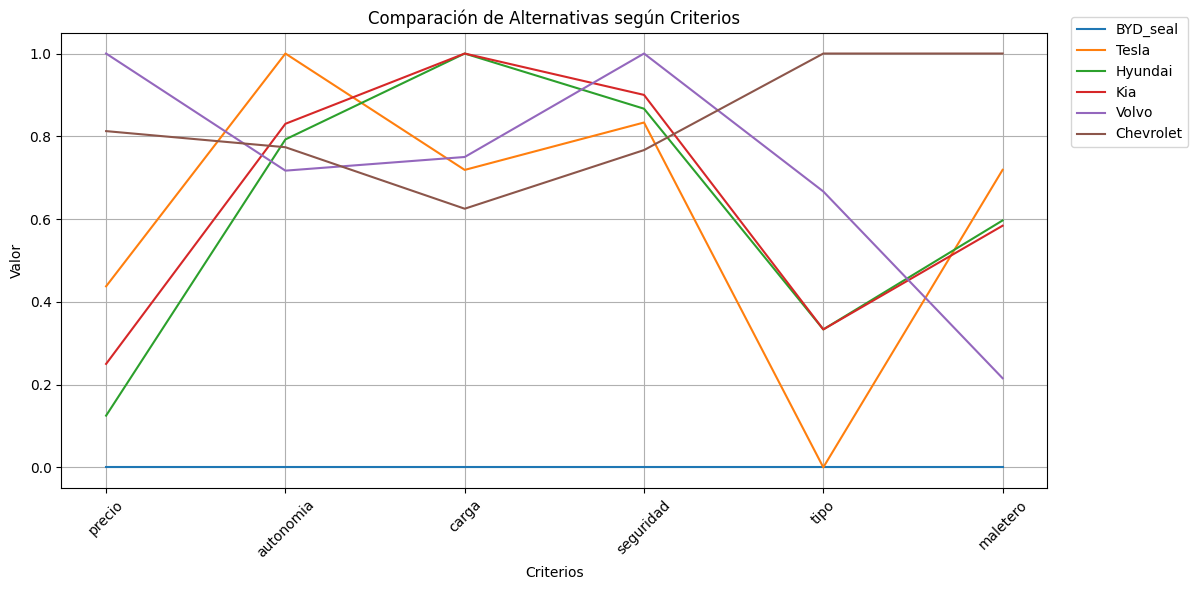

In [31]:
import matplotlib.pyplot as plt

# Transponer el DataFrame: filas = alternativas, columnas = criterios
matriznormalizada_transpuesta = matriz_normalizada.T

# Crear el gráfico
plt.figure(figsize=(12, 6))

# Graficar una línea por cada alternativa
for alt in matriznormalizada_transpuesta.index:
    plt.plot(matriznormalizada_transpuesta.columns, matriznormalizada_transpuesta.loc[alt], label=alt)

# Personalizar el gráfico
plt.title("Comparación de Alternativas según Criterios")
plt.xlabel("Criterios")
plt.ylabel("Valor")
plt.xticks(rotation=45)
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1.05), ncol=1)
plt.grid(True)
plt.tight_layout()

# Mostrar el gráfico
plt.show()


**Gráfico de Araña para todas las alternativas**

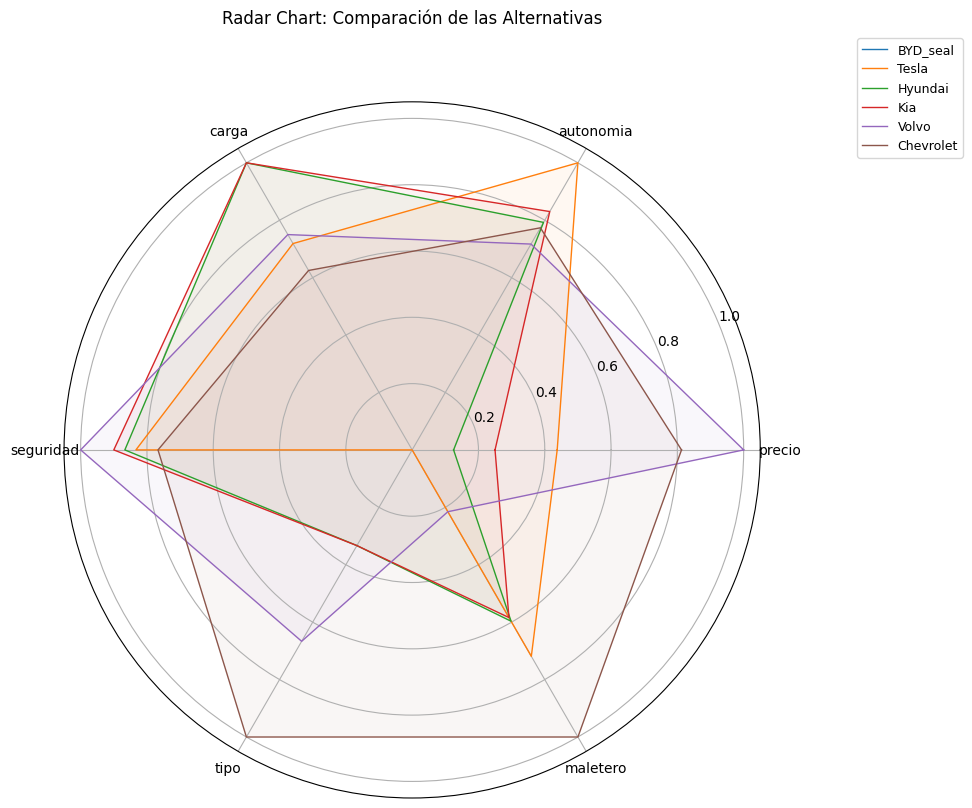

In [32]:
import numpy as np

# Paso 1: Preparar etiquetas y ángulos
labels = matriz_normalizada.index.tolist()
num_vars = len(labels)

# Repetir el primer valor al final para cerrar el gráfico circular
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

# Paso 2: Crear figura polar
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Paso 3: Dibujar cada alternativa
for alt in matriz_normalizada.columns:
    values = matriz_normalizada[alt].tolist()
    values += values[:1]  # Cierre del círculo
    ax.plot(angles, values, linewidth=1, label=alt)
    ax.fill(angles, values, alpha=0.05)  # Suaviza la visibilidad

# Paso 4: Personalizar ejes
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10)
ax.set_title("Radar Chart: Comparación de las Alternativas", y=1.1)

# Paso 5: Leyenda
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), ncol=1, fontsize=9)

plt.tight_layout()
plt.show()
